In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("ML Environment Ready!")
print("Scikit-learn version:", sklearn.__version__)

ML Environment Ready!
Scikit-learn version: 1.9.1


In [5]:
df = pd.read_csv("../data/used_cars.csv")
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [9]:
df.shape


(4009, 12)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB


In [12]:
df.columns.tolist()

['brand',
 'model',
 'model_year',
 'milage',
 'fuel_type',
 'engine',
 'transmission',
 'ext_col',
 'int_col',
 'accident',
 'clean_title',
 'price']

In [13]:
for column in df.columns:
    print(column, ":", df[column].dtype)
    

brand : str
model : str
model_year : int64
milage : str
fuel_type : str
engine : str
transmission : str
ext_col : str
int_col : str
accident : str
clean_title : str
price : str


In [14]:
for column in df.columns:
    print(f"\nColumn: {column}")
    print(df[column].head(3).tolist())


Column: brand
['Ford', 'Hyundai', 'Lexus']

Column: model
['Utility Police Interceptor Base', 'Palisade SEL', 'RX 350 RX 350']

Column: model_year
[2013, 2021, 2022]

Column: milage
['51,000 mi.', '34,742 mi.', '22,372 mi.']

Column: fuel_type
['E85 Flex Fuel', 'Gasoline', 'Gasoline']

Column: engine
['300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability', '3.8L V6 24V GDI DOHC', '3.5 Liter DOHC']

Column: transmission
['6-Speed A/T', '8-Speed Automatic', 'Automatic']

Column: ext_col
['Black', 'Moonlight Cloud', 'Blue']

Column: int_col
['Black', 'Gray', 'Black']

Column: accident
['At least 1 accident or damage reported', 'At least 1 accident or damage reported', 'None reported']

Column: clean_title
['Yes', 'Yes', nan]

Column: price
['$10,300', '$38,005', '$54,598']


In [16]:
df.isnull().sum()

brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

In [ ]:
df["price"] = (
    df["price"]
    .str.replace("$","",regex=False)
    .str.replace(",","",regex=False)

)
df["price"] = pd.to_numeric(df["price"], errors="coerce")



In [20]:
df["price"].head(10)

0    10300
1    38005
2    54598
3    15500
4    34999
5    14798
6    31000
7     7300
8    41927
9    69950
Name: price, dtype: int64

In [19]:
df["milage"].head(10)

0     51,000 mi.
1     34,742 mi.
2     22,372 mi.
3     88,900 mi.
4      9,835 mi.
5    136,397 mi.
6     84,000 mi.
7    242,000 mi.
8     23,436 mi.
9     34,000 mi.
Name: milage, dtype: str

In [21]:
df["milage"] = (
    df["milage"]
    .str.replace("mi.", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["milage"] = pd.to_numeric(df["milage"], errors="coerce")

In [23]:
print(df[["price", "milage"]].head())

print("\nData Types:")
print(df[["price", "milage"]].dtypes)

print("\nMissing Values:")
print(df[["price", "milage"]].isnull().sum())

   price  milage
0  10300   51000
1  38005   34742
2  54598   22372
3  15500   88900
4  34999    9835

Data Types:
price     int64
milage    int64
dtype: object

Missing Values:
price     0
milage    0
dtype: int64


In [25]:
columns_to_check = ["fuel_type", "accident", "clean_title"]

for column in columns_to_check:
    print(f"\n {column} ")
    print(df[column].value_counts(dropna=False))


 fuel_type 
fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

 accident 
accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

 clean_title 
clean_title
Yes    3413
NaN     596
Name: count, dtype: int64


In [26]:
df["price"].describe()

count    4.009000e+03
mean     4.455319e+04
std      7.871064e+04
min      2.000000e+03
25%      1.720000e+04
50%      3.100000e+04
75%      4.999000e+04
max      2.954083e+06
Name: price, dtype: float64

Median car price is $31,000, while mean price is approximately $44,553.

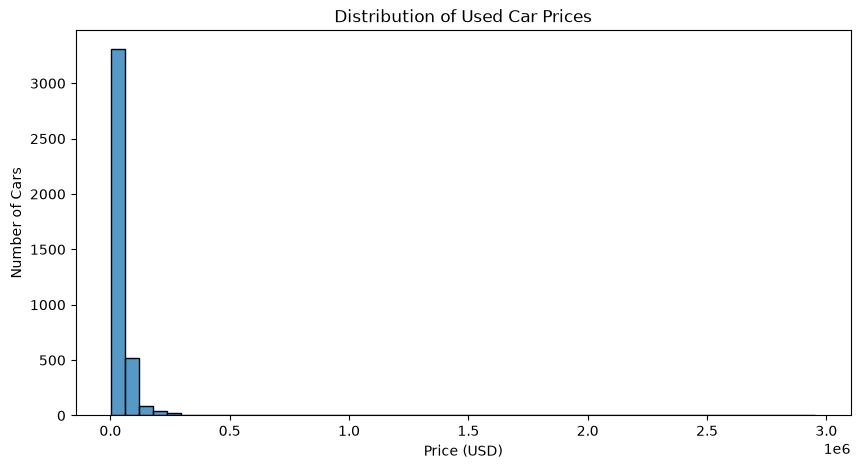

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(df["price"], bins=50)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Cars")

plt.show()

Price distribution is right-skewed, with some unusually expensive cars


In [28]:
df.nlargest(10, "price")[
    ["brand", "model", "model_year", "milage", "price"]
]

,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000,2954083
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330,1950995
3046,Porsche,Carrera GT Base,2005,4400,1599000
1356,Lamborghini,Aventador SVJ Base,2021,6987,749950
624,Rolls-Royce,Cullinan,2022,398,695000
979,Lamborghini,Aventador SVJ Base,2019,6929,649999
1615,Rolls-Royce,Phantom,2023,1560,599995
1508,Rolls-Royce,Phantom,2018,7585,599000
3655,Lamborghini,Aventador S Base,2018,5858,491836
1061,Dodge,Viper GTC,2017,1389,489995


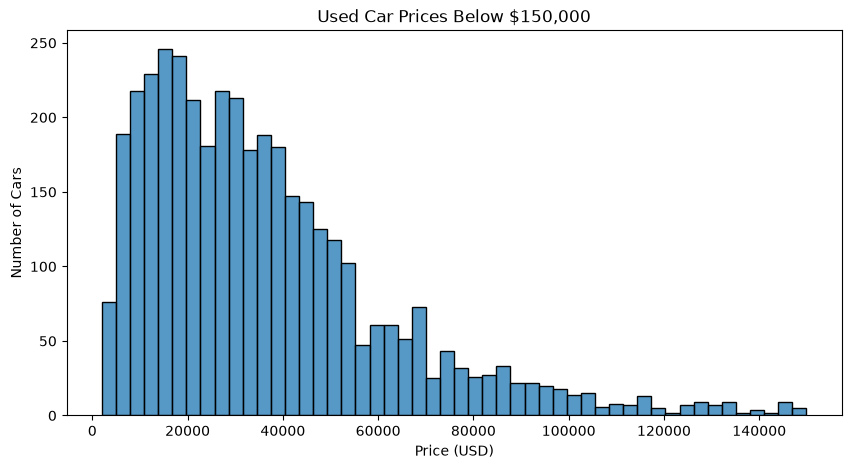

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df.loc[df["price"] < 150000, "price"],
    bins=50
)

plt.title("Used Car Prices Below $150,000")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Cars")

plt.show()

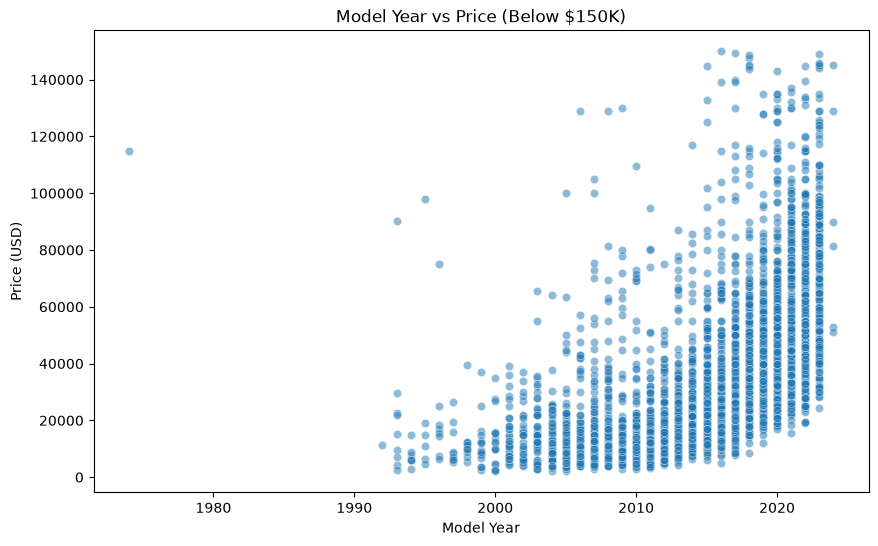

In [32]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df[df["price"] < 150000],
    x="model_year",
    y="price",
    alpha=0.5
)

plt.title("Model Year vs Price (Below $150K)")
plt.xlabel("Model Year")
plt.ylabel("Price (USD)")

plt.show()

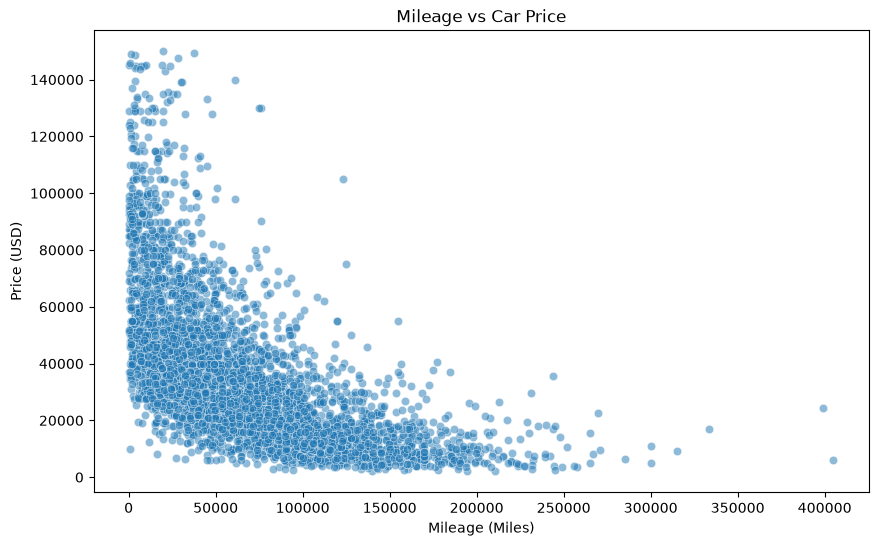

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df[df["price"] < 150000],
    x="milage",
    y="price",
    alpha=0.5
)

plt.title("Mileage vs Car Price")
plt.xlabel("Mileage (Miles)")
plt.ylabel("Price (USD)")

plt.show()

In [34]:
df[["model_year","milage","price"]].corr()

,model_year,milage,price
model_year,1.000000,-0.617720,0.199496
milage,-0.617720,1.000000,-0.305528
price,0.199496,-0.305528,1.000000


Mileage and price correlation: -0.3055.


Model year and price correlation: +0.1995.


Model year and mileage correlation: -0.6177.

In [35]:
df.duplicated().sum()

np.int64(0)

In [36]:
print("Negative or zero prices:", (df["price"] <= 0).sum())

print("Negative mileage:", (df["milage"] < 0).sum())

print("Future model years:", (df["model_year"] > 2027).sum())

print("Missing prices:", df["price"].isna().sum())

print("Missing mileage:", df["milage"].isna().sum())

Negative or zero prices: 0
Negative mileage: 0
Future model years: 0
Missing prices: 0
Missing mileage: 0


In [ ]:
from sklearn.model_selection import train_test_split

X = df[["model_year", "milage"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42


In [39]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3207, 2)
X_test: (802, 2)
y_train: (3207,)
y_test: (802,)


In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [41]:
print("Before Scaling:")
print(X_train.head())

print("\nAfter Scaling:")
print(X_train_scaled[:5])

Before Scaling:
      model_year  milage
2473        2018   73049
1338        2023    9980
1613        2016   55250
1610        2017   77300
2600        2018   33700

After Scaling:
[[ 0.40489434  0.15463515]
 [ 1.23386276 -1.04838992]
 [ 0.07330697 -0.18487623]
 [ 0.23910065  0.23572189]
 [ 0.40489434 -0.59593698]]


In [ ]:
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

print("Mean:", X_train_scaled.mean(axis=0))
print("Std:", X_train_scaled.std(axis=0))

X_train_scaled: (3207, 2)
X_test_scaled: (802, 2)
Mean: [ 1.31739542e-14 -7.92076795e-17]
Std: [1. 1.]


In [58]:
X_train_np = X_train_scaled
y_train_np = y_train.to_numpy()

w = np.zeros(2)
b = 0.0

print("X Shape:", X_train_np.shape)
print("y Shape:", y_train_np.shape)
print("Weights:", w)
print("Bias:", b)

X Shape: (3207, 2)
y Shape: (3207,)
Weights: [0. 0.]
Bias: 0.0


In [59]:
def predict(X, w, b):

    m = X.shape[0]
    predictions = np.zeros(m)

    for i in range(m):

        f_wb = w[0] * X[i][0] + w[1] * X[i][1] + b

        predictions[i] = f_wb

    return predictions

J(w,b) = 1/2m (yhat[i] - y[i])**2

In [60]:
def compute_cost(X, y, w, b):

    m = X.shape[0]
    cost = 0

    for i in range(m):

        f_wb = w[0] * X[i][0] + w[1] * X[i][1] + b

        error = f_wb - y[i]

        cost = cost + error**2

    total_cost = cost / (2 * m)

    return total_cost

In [61]:
def compute_gradient(X, y, w, b):

    m = X.shape[0]

    dj_dw = np.zeros(2)
    dj_db = 0

    for i in range(m):

        f_wb = w[0] * X[i][0] + w[1] * X[i][1] + b

        error = f_wb - y[i]

        dj_dw[0] = dj_dw[0] + error * X[i][0]
        dj_dw[1] = dj_dw[1] + error * X[i][1]

        dj_db = dj_db + error

    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db

In [62]:
initial_predictions = predict(X_train_np, w, b)

initial_cost = compute_cost(X_train_np, y_train_np, w, b)

dj_dw, dj_db = compute_gradient(
    X_train_np,
    y_train_np,
    w,
    b
)

print("First 5 Predictions:", initial_predictions[:5])
print("Initial Cost:", initial_cost)
print("Gradient w:", dj_dw)
print("Gradient b:", dj_db)

First 5 Predictions: [0. 0. 0. 0. 0.]
Initial Cost: 2240457902.9357657
Gradient w: [-18085.80312286  22628.2188372 ]
Gradient b: -43125.75678203929


In [72]:
def gradient_descent(X, y, w, b, alpha, iterations):

    cost_history = []

    for i in range(iterations):

        dj_dw, dj_db = compute_gradient(X, y, w, b)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if i % 100 == 0:
            cost = compute_cost(X, y, w, b)
            cost_history.append(cost)

            print(f"Iteration {i}: Cost = {cost:.2f}")

    return w, b, cost_history

In [76]:
alpha = 0.01
iterations = 1000

w_initial = np.zeros(2)
b_initial = 0.0

w_final, b_final, cost_history = gradient_descent(
    X_train_np,
    y_train_np,
    w_initial,
    b_initial,
    alpha,
    iterations
)

print("\nFinal Weights:", w_final)
print("Final Bias:", b_final)

Iteration 0: Cost = 2213628467.70
Iteration 100: Cost = 1178626686.57
Iteration 200: Cost = 1060399236.63
Iteration 300: Cost = 1044336520.53
Iteration 400: Cost = 1041708449.83
Iteration 500: Cost = 1041121088.48
Iteration 600: Cost = 1040932641.47
Iteration 700: Cost = 1040856425.55
Iteration 800: Cost = 1040822554.24
Iteration 900: Cost = 1040807033.27

Final Weights: [  6786.85483131 -18391.69344118]
Final Bias: 43123.89498932339


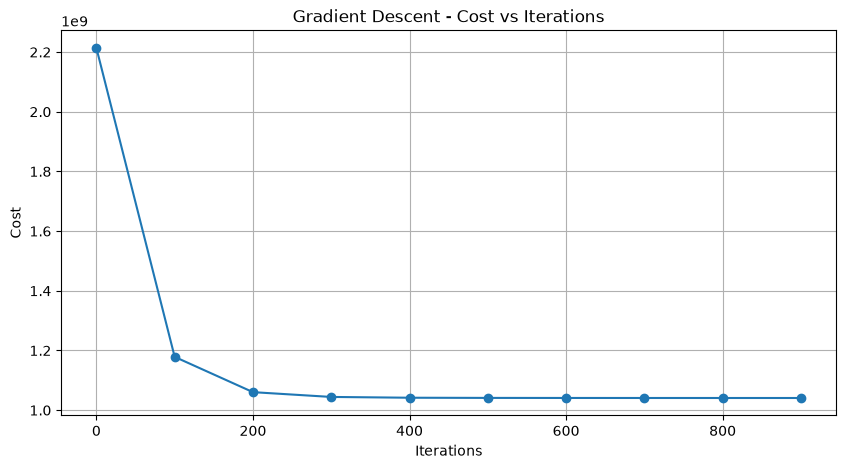

In [77]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(0, iterations, 100),
    cost_history,
    marker="o"
)

plt.title("Gradient Descent - Cost vs Iterations")
plt.xlabel("Iterations")
plt.ylabel("Cost")

plt.grid(True)
plt.show()

In [78]:
y_pred = predict(X_test_scaled, w_final, b_final)

print("First 5 Predictions:")
print(y_pred[:5])

print("\nActual Prices:")
print(y_test.iloc[:5].to_numpy())

First 5 Predictions:
[50765.81923076 30273.93780416 37359.20503704 54281.66737613
 62164.56054649]

Actual Prices:
[28000  5900 41000 40250 77999]


In [79]:
y_test_np = y_test.to_numpy()

absolute_errors = np.abs(y_pred - y_test_np)

mae = np.mean(absolute_errors)

print("Test MAE:", mae)

Test MAE: 30852.378167036786


In [80]:
# Calculate the average price from training data
mean_price = np.mean(y_train_np)

# Predict the same average price for every test car
baseline_predictions = np.full(
    len(y_test_np),
    mean_price
)

# Calculate baseline MAE
baseline_mae = np.mean(
    np.abs(baseline_predictions - y_test_np)
)

print("Baseline MAE:", baseline_mae)
print("Our Model MAE:", mae)

Baseline MAE: 35276.1590714514
Our Model MAE: 30852.378167036786


In [81]:
squared_errors = (y_pred - y_test_np) ** 2

mse = np.mean(squared_errors)

rmse = np.sqrt(mse)

print("Test RMSE:", rmse)

Test RMSE: 140909.40675745485


In [82]:
ss_res = np.sum((y_test_np - y_pred) ** 2)

ss_tot = np.sum(
    (y_test_np - np.mean(y_test_np)) ** 2
)

r2 = 1 - (ss_res / ss_tot)

print("Test R²:", r2)

Test R²: 0.028577416477342354


In [83]:
results = X_test.copy()

results["Actual Price"] = y_test
results["Predicted Price"] = y_pred

results["Absolute Error"] = np.abs(
    results["Actual Price"] - results["Predicted Price"]
)

results.head()

,model_year,milage,Actual Price,Predicted Price,Absolute Error
2580,2018,50992,28000,50765.819231,22765.819231
3660,2004,64500,5900,30273.937804,24373.937804
897,2017,86000,41000,37359.205037,3640.794963
2091,2013,24933,40250,54281.667376,14031.667376
1044,2018,18500,77999,62164.560546,15834.439454


In [84]:
results.nlargest(10, "Absolute Error")

,model_year,milage,Actual Price,Predicted Price,Absolute Error
693,2005,32000,2954083,42800.703321,2.911282e+06
229,2011,6330,1950995,58557.478034,1.892438e+06
3046,2005,4400,1599000,52483.248572,1.546517e+06
1061,2017,1389,489995,67042.170120,4.229528e+05
203,2005,1897,429998,53361.343165,3.766367e+05
1811,2016,3254,399900,65262.679016,3.346373e+05
3816,2022,3420,399950,71955.749413,3.279943e+05
254,2023,278,359991,74183.233643,2.858078e+05
76,2023,255,359991,74191.302431,2.857997e+05
450,2021,850,314900,71732.131069,2.431679e+05


In [85]:
worst_predictions = results.nlargest(10, "Absolute Error")

worst_cars = df.loc[
    worst_predictions.index,
    ["brand", "model"]
]

worst_predictions = worst_predictions.join(worst_cars)

worst_predictions

,model_year,milage,Actual Price,Predicted Price,Absolute Error,brand,model
693,2005,32000,2954083,42800.703321,2.911282e+06,Maserati,Quattroporte Base
229,2011,6330,1950995,58557.478034,1.892438e+06,Bugatti,Veyron 16.4 Grand Sport
3046,2005,4400,1599000,52483.248572,1.546517e+06,Porsche,Carrera GT Base
1061,2017,1389,489995,67042.170120,4.229528e+05,Dodge,Viper GTC
203,2005,1897,429998,53361.343165,3.766367e+05,Ford,GT
1811,2016,3254,399900,65262.679016,3.346373e+05,Lamborghini,Aventador LP700-4
3816,2022,3420,399950,71955.749413,3.279943e+05,Rolls-Royce,Cullinan
254,2023,278,359991,74183.233643,2.858078e+05,Lamborghini,Huracan Tecnica Coupe
76,2023,255,359991,74191.302431,2.857997e+05,Lamborghini,Huracan Tecnica Coupe
450,2021,850,314900,71732.131069,2.431679e+05,Rolls-Royce,Ghost Base
